## Semiconductor Lab B7 - Task 3 & 4

### Task 3 
Measure the spectrum of spontaneous emission of the laser diode by operating it at a very
low current density as LED. Determine the effective carrier temperature from the gradient
in the high-energy range by using the line shape model for spontaneous emission.
### Task 4
 Measure the spectrum at a higher operating current below the threshold and again
determine the effective temperature. Compare the result with (3) and find conclusions.

In [1]:
%matplotlib inline

from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt
import pandas as pd
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from scipy import constants
from scipy.optimize import curve_fit
from scipy.signal import peak_widths

from b7.python.config import DATA_DIR, DOUBLE_COLUMN, PLOTS_DIR
from b7.python.helper import HC_EV_NM, read_spectrum

In [2]:
data_dir: Path = DATA_DIR / "task_3_4_5"
export_dir: Path = PLOTS_DIR

### Import Data

- `0.1mA.txt` is the LED regime of task 3
- `9.9mA.txt` the higher sub-threshold current of task 4.

In [3]:
df_led: pd.DataFrame = read_spectrum(data_dir / "0.1mA.txt")
df_sub: pd.DataFrame = read_spectrum(data_dir / "9.9mA.txt")

### Fit Data

#### Line Shape Model

The monochromator steps in constant intervals of wavelength and the detector measures power, so
the lock-in signal is proportional to the spectral power density per wavelength $p_\lambda$.
Weighting the spontaneous emission rate with the photon energy and transforming
$\mathrm{d}E = hc/\lambda^2\,\mathrm{d}\lambda$ gives

$$
p_{\lambda}(\lambda)\propto\frac{1}{\lambda^{4}}\sqrt{\frac{hc}{\lambda}-E_{\mathrm{g}}}\,\exp\left( -\frac{\frac{hc}{\lambda}-E_{\mathrm{g}}}{k_{\mathrm B}T_\mathrm{c}} \right),
$$

which is fitted directly to the measured signal, without converting the spectrum to a density
per energy first.

In [4]:
WINDOW_LED: tuple[float, float] = (732.0, 775.0)
WINDOW_SUB: tuple[float, float] = (726.0, 768.0)

KB_EV: float = constants.k / constants.e  # Boltzmann constant in eV/K

In [5]:
def log_spontaneous_emission(
    lambda_nm: npt.NDArray[np.float64], E_g: float, T_c: float, ln_A: float
) -> npt.NDArray[np.float64]:
    """Natural logarithm of the spontaneous emission power density per wavelength p_lambda.

    lambda_nm in nm, E_g in eV and T_c in K. The exponential is written in terms of E - E_g
    rather than E so that ln_A does not have to absorb E_g / k T_c, and lambda is referred to
    780 nm, so that ln_A stays of order one and the fit is well scaled. Clipping keeps the
    logarithm of E - E_g defined for E < E_g.
    """
    x: npt.NDArray[np.float64] = np.clip(HC_EV_NM / lambda_nm - E_g, 1e-12, None)
    return ln_A - 4 * np.log(lambda_nm / 780.0) + 0.5 * np.log(x) - x / (KB_EV * T_c)

In [6]:
mask_led: pd.Series = df_led["lambda_nm"].between(*WINDOW_LED) & (df_led["signal"] > 0)
lambda_led: npt.NDArray[np.float64] = df_led.loc[mask_led, "lambda_nm"].to_numpy()
ln_p_led: npt.NDArray[np.float64] = np.log(df_led.loc[mask_led, "signal"].to_numpy())

# The line shape E^4 sqrt(E - E_g) exp(-(E - E_g) / k T_c) of p_lambda has its maximum where
# d ln p / dE = 4 / E + 1 / (2 x) - 1 / (k T_c) = 0 with x = E - E_g, i.e. at
# x = (k T_c / 2) / (1 - 4 k T_c / E). Instead of fitting E_g freely it is tied to the measured
# peak of the spectrum, E = E_peak, through this exact relation.
lambda_peak_led: float = df_led.loc[df_led["signal"].idxmax(), "lambda_nm"]
E_peak_led: float = HC_EV_NM / lambda_peak_led

(T_c_led, ln_A_led), cov_led = curve_fit(
    lambda lambda_nm, T_c, ln_A: log_spontaneous_emission(
        lambda_nm, E_peak_led - (KB_EV * T_c / 2) / (1 - 4 * KB_EV * T_c / E_peak_led), T_c, ln_A
    ),
    lambda_led,
    ln_p_led,
    p0=[300.0, 0.0],
    bounds=([50.0, -60.0], [3000.0, 60.0]),
)
T_c_led_err, _ = np.sqrt(np.diag(cov_led))
E_g_led: float = E_peak_led - (KB_EV * T_c_led / 2) / (1 - 4 * KB_EV * T_c_led / E_peak_led)
# dE_g/dT_c = -(k / 2) / (1 - 4 k T_c / E_peak)^2
E_g_led_err: float = KB_EV * T_c_led_err / 2 / (1 - 4 * KB_EV * T_c_led / E_peak_led) ** 2

# peak_widths interpolates linearly between the scan points that bracket the half maximum,
# so the FWHM is not limited to multiples of the scan step.
half_max_led: float = df_led["signal"].max() / 2
fwhm_led_samples, *_ = peak_widths(df_led["signal"], [df_led["signal"].argmax()], rel_height=0.5)
fwhm_led_nm: float = fwhm_led_samples[0] * df_led["lambda_nm"].diff().mean()

fit_led = {
    "n_points": int(mask_led.sum()),
    "fwhm_nm": fwhm_led_nm,
    "n_points_above_half": int((df_led["signal"] >= half_max_led).sum()),
    "lambda_peak_nm": lambda_peak_led,
    "E_peak": E_peak_led,
    "E_g": E_g_led,
    "E_g_err": E_g_led_err,
    "T_c": T_c_led,
    "T_c_err": T_c_led_err,
    "kT_meV": KB_EV * T_c_led * 1e3,
}
pprint(fit_led)

{'E_g': np.float64(1.5732070011861545),
 'E_g_err': np.float64(0.00021052604185522764),
 'E_peak': np.float64(1.5854756832890058),
 'T_c': np.float64(268.1446915694025),
 'T_c_err': np.float64(4.3330260399176534),
 'fwhm_nm': np.float64(20.138804932982097),
 'kT_meV': np.float64(23.10692169728672),
 'lambda_peak_nm': np.float64(782.0),
 'n_points': 22,
 'n_points_above_half': 10}


In [7]:
mask_sub: pd.Series = df_sub["lambda_nm"].between(*WINDOW_SUB) & (df_sub["signal"] > 0)
lambda_sub: npt.NDArray[np.float64] = df_sub.loc[mask_sub, "lambda_nm"].to_numpy()
ln_p_sub: npt.NDArray[np.float64] = np.log(df_sub.loc[mask_sub, "signal"].to_numpy())

# E_g tied to the peak of this spectrum, as for the LED
lambda_peak_sub: float = df_sub.loc[df_sub["signal"].idxmax(), "lambda_nm"]
E_peak_sub: float = HC_EV_NM / lambda_peak_sub

(T_c_sub, ln_A_sub), cov_sub = curve_fit(
    lambda lambda_nm, T_c, ln_A: log_spontaneous_emission(
        lambda_nm, E_peak_sub - (KB_EV * T_c / 2) / (1 - 4 * KB_EV * T_c / E_peak_sub), T_c, ln_A
    ),
    lambda_sub,
    ln_p_sub,
    p0=[300.0, 0.0],
    bounds=([50.0, -60.0], [3000.0, 60.0]),
)
T_c_sub_err, _ = np.sqrt(np.diag(cov_sub))
E_g_sub: float = E_peak_sub - (KB_EV * T_c_sub / 2) / (1 - 4 * KB_EV * T_c_sub / E_peak_sub)
# dE_g/dT_c = -(k / 2) / (1 - 4 k T_c / E_peak)^2
E_g_sub_err: float = KB_EV * T_c_sub_err / 2 / (1 - 4 * KB_EV * T_c_sub / E_peak_sub) ** 2

half_max_sub: float = df_sub["signal"].max() / 2
fwhm_sub_samples, *_ = peak_widths(df_sub["signal"], [df_sub["signal"].argmax()], rel_height=0.5)
fwhm_sub_nm: float = fwhm_sub_samples[0] * df_sub["lambda_nm"].diff().mean()

fit_sub = {
    "n_points": int(mask_sub.sum()),
    "fwhm_nm": fwhm_sub_nm,
    "n_points_above_half": int((df_sub["signal"] >= half_max_sub).sum()),
    "lambda_peak_nm": lambda_peak_sub,
    "E_peak": E_peak_sub,
    "E_g": E_g_sub,
    "E_g_err": E_g_sub_err,
    "T_c": T_c_sub,
    "T_c_err": T_c_sub_err,
    "kT_meV": KB_EV * T_c_sub * 1e3,
}
pprint(fit_sub)

{'E_g': np.float64(1.5794971609504527),
 'E_g_err': np.float64(9.116175355530793e-05),
 'E_peak': np.float64(1.5895410055538495),
 'T_c': np.float64(221.89141777307827),
 'T_c_err': np.float64(1.9170639676859242),
 'fwhm_nm': np.float64(4.7666287352897),
 'kT_meV': np.float64(19.12112294960499),
 'lambda_peak_nm': np.float64(780.0),
 'n_points': 22,
 'n_points_above_half': 2}


#### Composition of the Active Layer

For the direct gap of $\mathrm{Al}_x\mathrm{Ga}_{1-x}\mathrm{As}$ ($x < 0.4$) at room temperature,
$E_\mathrm{g}(x) = 1.42\,\mathrm{eV} + 1.247\,\mathrm{eV} \cdot x$ (Grundmann, Table 1.1 and Fig. 6.24c). Solved for $x$ with the
band gap of the LED spectrum. The uncertainty of $E_\mathrm{g}$ is one 2 nm scan step at the peak,
$\Delta E = hc\,\Delta\lambda / \lambda^2$.

In [8]:
E_G_GAAS: float = 1.42  # eV, direct gap of GaAs at room temperature (Grundmann, Table 1.1)
E_G_SLOPE: float = 1.247  # eV per unit aluminum fraction x, direct gap for x < 0.4 (Grundmann, Fig. 6.24c)

E_g_led_grid_err: float = HC_EV_NM * 2.0 / lambda_peak_led**2  # one 2 nm scan step at the peak
x_led: float = (E_g_led - E_G_GAAS) / E_G_SLOPE
x_led_err: float = E_g_led_grid_err / E_G_SLOPE

pprint({"E_g_grid_err_eV": E_g_led_grid_err, "x": x_led, "x_err": x_led_err})

{'E_g_grid_err_eV': np.float64(0.004054925021199503),
 'x': np.float64(0.12286046606748563),
 'x_err': np.float64(0.0032517442030469148)}


### Plot Data

#### Preparation

In [9]:
# Smooth line shape curve over each fitted window, padded a bit on either side
pad = 100.0
lambda_led_curve = np.linspace(lambda_led.min() - pad, lambda_led.max() + pad, 400)
p_led_curve = np.exp(log_spontaneous_emission(lambda_led_curve, E_g_led, T_c_led, ln_A_led))

lambda_sub_curve = np.linspace(lambda_sub.min() - pad, lambda_sub.max() + pad, 400)
p_sub_curve = np.exp(log_spontaneous_emission(lambda_sub_curve, E_g_sub, T_c_sub, ln_A_sub))

# 1/lambda^4 and square root divided out, so the carrier temperature is simply the slope of a
# straight line in E; only points above E_g with positive signal have a logarithm
above_led: pd.Series = (df_led["E_eV"] > E_g_led) & (df_led["signal"] > 0)
E_led_flat = df_led.loc[above_led, "E_eV"].to_numpy()
lambda_led_flat = df_led.loc[above_led, "lambda_nm"].to_numpy()
ln_p_led_flat = (
    np.log(df_led.loc[above_led, "signal"].to_numpy())
    + 4 * np.log(lambda_led_flat / 780.0)
    - 0.5 * np.log(E_led_flat - E_g_led)
)
ln_p_led_flat_fit = ln_A_led - (E_led_flat - E_g_led) / (KB_EV * T_c_led)

above_sub: pd.Series = (df_sub["E_eV"] > E_g_sub) & (df_sub["signal"] > 0)
E_sub_flat = df_sub.loc[above_sub, "E_eV"].to_numpy()
lambda_sub_flat = df_sub.loc[above_sub, "lambda_nm"].to_numpy()
ln_p_sub_flat = (
    np.log(df_sub.loc[above_sub, "signal"].to_numpy())
    + 4 * np.log(lambda_sub_flat / 780.0)
    - 0.5 * np.log(E_sub_flat - E_g_sub)
)
ln_p_sub_flat_fit = ln_A_sub - (E_sub_flat - E_g_sub) / (KB_EV * T_c_sub)


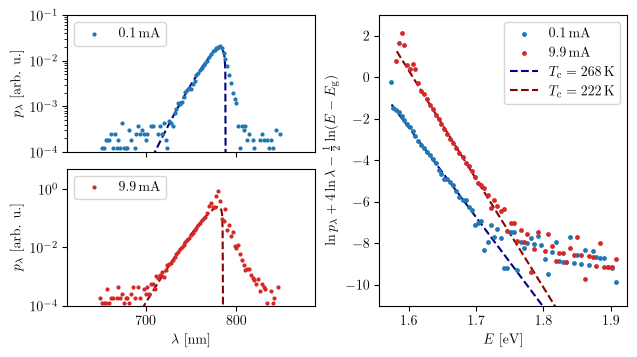

In [10]:
with plt.rc_context(DOUBLE_COLUMN):
    fig: Figure = plt.figure(layout="constrained")
    axs: dict[str, Axes] = fig.subplot_mosaic([["led", "flat"], ["sub", "flat"]])
    ax_led: Axes = axs["led"]
    ax_sub: Axes = axs["sub"]
    ax_flat: Axes = axs["flat"]
    ax_led.sharex(ax_sub)

    ax_led.scatter(df_led["lambda_nm"], df_led["signal"], s=4, color="tab:blue", label=r"\qty{0.1}{\milli\ampere}")
    ax_led.plot(lambda_led_curve, p_led_curve, color="navy", linestyle="--", zorder=-1)
    ax_led.set_yscale("log")
    ax_led.set_ylim(1e-4, 1e-1)
    ax_led.set_ylabel(r"$p_\lambda$ [arb. u.]")
    ax_led.tick_params(labelbottom=False)
    ax_led.legend(loc="upper left")

    ax_sub.scatter(df_sub["lambda_nm"], df_sub["signal"], s=4, color="tab:red", label=r"\qty{9.9}{\milli\ampere}")
    ax_sub.plot(lambda_sub_curve, p_sub_curve, color="darkred", linestyle="--", zorder=-1)
    ax_sub.set_yscale("log")
    ax_sub.set_ylim(1e-4, 5)
    ax_sub.set_ylabel(r"$p_\lambda$ [arb. u.]")
    ax_sub.set_xlabel(r"$\lambda$ [\unit{\nano\meter}]")
    ax_sub.legend(loc="upper left")

    ax_flat.scatter(E_led_flat, ln_p_led_flat, s=6, color="tab:blue", label=r"\qty{0.1}{\milli\ampere}")
    ax_flat.scatter(E_sub_flat, ln_p_sub_flat, s=6, color="tab:red", label=r"\qty{9.9}{\milli\ampere}")
    ax_flat.plot(
        E_led_flat,
        ln_p_led_flat_fit,
        color="navy",
        linestyle="--",
        zorder=-1,
        label=rf"$T_\mathrm{{c}} = \qty{{{T_c_led:.0f}}}{{\kelvin}}$",
    )
    ax_flat.plot(
        E_sub_flat,
        ln_p_sub_flat_fit,
        color="darkred",
        linestyle="--",
        zorder=-1,
        label=rf"$T_\mathrm{{c}} = \qty{{{T_c_sub:.0f}}}{{\kelvin}}$",
    )
    ax_flat.set_ylim(-11, 3)
    ax_flat.set_xlabel(r"$E$ [\unit{\electronvolt}]")
    ax_flat.set_ylabel(r"$\ln p_\lambda + 4 \ln \lambda - \frac{1}{2} \ln (E - E_\mathrm{g})$")
    ax_flat.legend(loc="upper right")

    fig.savefig(export_dir / "task3.pdf")
    plt.show()

### Result

|        | $I_\mathrm{D}$ | FWHM   | $E_\mathrm{g}$              | $T_\mathrm{c}$   |
|--------|----------------|--------|-----------------------------|------------------|
| Task 3 | 0.1 mA         | 20 nm  | $(1.573 \pm 0.004)$ eV      | $(268 \pm 4)$ K  |
| Task 4 | 9.9 mA         | 4.8 nm | $(1.579 \pm 0.004)$ eV      | $(222 \pm 2)$ K  |

**Method**
- Fit of $\ln p_\lambda$ to the line shape model on the high-energy flank only (732-775 nm and 726-768 nm).
- $E_\mathrm{g}$ tied to the measured peak via the exact maximum of $p_\lambda$, $E_\mathrm{peak} = E_\mathrm{g} + (k_\mathrm{B}T_\mathrm{c}/2)/(1 - 4k_\mathrm{B}T_\mathrm{c}/E_\mathrm{peak})$, separately for each spectrum (peaks at 782 nm and 780 nm); only $T_\mathrm{c}$ and amplitude are free.
- Uncertainty of $E_\mathrm{g}$: one 2 nm scan step at the peak. Uncertainties of $T_\mathrm{c}$: fit only.
- At 9.9 mA the peak is the amplified part of the line, so $E_\mathrm{g}$ from the peak is less reliable than for the LED.

**Task 3 (0.1 mA)**
- Broad line (FWHM 20 nm): spontaneous emission only, LED operation.
- Model describes the flank over the whole fit window.
- $T_\mathrm{c} = 268$ K, about 27 K below room temperature (295 K). Expected: $T_\mathrm{c} \geq T_\mathrm{lattice}$.
- $E_\mathrm{g} = 1.573$ eV (788 nm), i.e. an aluminum fraction $x = 0.123 \pm 0.003$ of the AlGaAs active layer (composition cell above).

**Task 4 (9.9 mA)**
- Line narrows to 4.8 nm (only two scan points above half maximum): amplified spontaneous emission below threshold.
- $T_\mathrm{c} = 222$ K, lower than at 0.1 mA. Not physical as a carrier temperature.
- Gain decreases with photon energy above the band edge and turns into absorption above $\Delta F$, which steepens the high-energy flank and lowers the apparent $T_\mathrm{c}$.
- The fit measures gain times spontaneous spectrum, not the carrier distribution alone.

**Comparison and systematics**
- Expected: $T_\mathrm{c}$ increases with current (carrier heating). Observed: decrease, so the 9.9 mA spectrum is dominated by gain.
- Both values below room temperature: spectral response of grating and detector not calibrated, tilts the flank in the same direction for both currents.
- The exact maximum of $p_\lambda$ is used for $E_\mathrm{peak}$; the former approximation $E_\mathrm{g} + k_\mathrm{B}T_\mathrm{c}/2$ would shift $E_\mathrm{g}$ by 0.7 meV and $T_\mathrm{c}$ by 0.5 K, below the 2 nm step.
- Result depends on how $E_\mathrm{g}$ is determined: with $E_\mathrm{g}$ free (LED window up to 782 nm), $T_\mathrm{c} = 277$ K and 228 K.